# Extracting the UB matrix from I16 NeXus files
This short notebook describes the different typles of UB matrix stored in the I16 NeXus file and how to convert between these.

### *Notebook Notes*
This notebook will run with any modern version of python and requires *numpy*, *h5py* and *jupyter* installed. Features at the end of the notebook require *mmg_toolbox*, which can be installed easily using:
```bash
python -m pip install mmg_toolbox
```

In [1]:
import numpy as np
import h5py

In [19]:
# Example I16 NeXus file
filename = "/dls/science/groups/das/ExampleData/i16/msmapper_test/1161043.nxs"

# Extract UB matrix values from file
with h5py.File(filename) as hdf:
    # Standard NeXus fields
    ub_matrix = hdf['/entry/sample/ub_matrix'][0]  # stored as [1, 3, 3]
    unit_cell = hdf['/entry/sample/unit_cell'][0]  # stored as [1, 6]
    orientation_matrix = hdf['/entry/sample/orientation_matrix'][0]  # stored as [1, 3, 3]
    # I16 Specific fields, stored DiffCalc data
    diffcalc_ub = np.zeros([3, 3])
    for n in range(3):
        for m in range(3):
            diffcalc_ub[n, m] = hdf[f'/entry/instrument/xtlinfo_extra/UB{n+1}{m+1}'][...]

print('/entry/sample/ub_matrix')
print(ub_matrix)
print('/entry/sample/unit_cell')
print(unit_cell)
print('/entry/sample/orientation_matrix')
print(orientation_matrix)
print('/entry/instrument/xtlinfo_extra/UB')
print(diffcalc_ub)

/entry/sample/ub_matrix
[[ 0.00696873  0.02018896  0.08927625]
 [ 0.11899189 -0.19408108  0.00534921]
 [ 0.19443249  0.11805323 -0.00647348]]
/entry/sample/unit_cell
[ 4.3848   4.3848  11.15196 90.      90.      90.     ]
/entry/sample/orientation_matrix
[[ 0.03055647  0.08852457  0.99560519]
 [ 0.52175563 -0.85100672  0.05965416]
 [ 0.85254757  0.5176398  -0.07219196]]
/entry/instrument/xtlinfo_extra/UB
[[ 0.74764808 -1.21944739  0.03361007]
 [ 1.22165535  0.74175031 -0.04067406]
 [ 0.0437858   0.126851    0.56093924]]


## UB Matrix Definitions

| field                                | convention                  | coordinate system                       |
|--------------------------------------|-----------------------------|-----------------------------------------|
| /entry/sample/ub_matrix              | crystallography (no $2\pi$) | lab: $\phi$-axis along $+y$             |
| /entry/instrument/xtlinfo_extra/UB## | physics ($2\pi$)            | diffractometer: $\phi$-axis along $+z$ |

### /entry/sample/ub_matrix & /entry/sample/orientation_matrix
*See https://manual.nexusformat.org/classes/base_classes/NXsample.html*

UB matrix of single crystal sample using Busing-Levy convention: [W. R. Busing and H. A. Levy (1967). Acta Cryst. 22, 457-464](https://doi.org/10.1107/S0365110X67000970). This is the multiplication of the orientation_matrix, given above, with the matrix which can be derived from the lattice constants.

**Note:** The reciprocal lattice vectors in this matrix use the crystallography (no $2\pi$) and are definition are defined by

$$
\vec{b_1} = \frac{\vec{a_2}\times \vec{a_3}}{\vec{a_1} \cdot  (\vec{a_2} \times \vec{a_3}) }
$$

The B matrix is defined by:

$$
\mathbf{B} =
\begin{pmatrix}
b_1 & b_2\cos{\beta_3} & b_3 \cos \beta_2 \\
0 & b_2 \sin \beta_3 & -b_3 \sin \beta_2 \cos \alpha_1 \\
0 & 0 & 1/a_3
\end{pmatrix}
$$

where $a_i$ and $\alpha_i$ are the direct lattice parameters and $b_i$ and $\beta_i$ are the reciprocal lattice parameters.

The U matrix, or *orientation_matrix* is the orthogonal matrix that relates the orientation of the crystal to the diffractometer $\phi$-axis in the lab frame, where the $\phi$-axis is parallel to the horizontal $y$-axis (the plane of the synchrotron).

### /entry/instrument/xtlinfo_extra/UB##
*See https://diffcalc.readthedocs.io/en/latest/youmanual.html#theory*
This UB matrix is the one used by the software DiffCalc on the beamline to generate reflections. The matrices are the same but there is a difference in convention between them - the DiffCalc B matrix uses the *physics* definition of the reciprocal lattice, including $2\pi$, and the DiffCalc orientation matrix describes the diffractometer $\phi$ axis as vertical, where as it is horizontal in the lab frame.

Transforming from the DiffCalc UB matrix to the NeXus UB matrix is a simple transformation:

$$
\mathbf{UB_{NeXus}} =
\begin{pmatrix}
0 & 0 & 1 \\
1 & 0 & 0 \\
0 & 1 & 0
\end{pmatrix}
\cdot
\mathbf{UB_{DiffCalc}} / 2\pi
$$

Likewise, the transformation back:

$$
\mathbf{UB_{DiffCalc}} =
2\pi
\begin{pmatrix}
0 & 1 & 0 \\
0 & 0 & 1 \\
1 & 0 & 0
\end{pmatrix}
\cdot
\mathbf{UB_{NeXus}}
$$


In [16]:
diffcalc2nexus = [[0, 0, 1], [1, 0, 0], [0, 1, 0]]

diffcalc_ub_tr = (diffcalc2nexus @ diffcalc_ub) / (2 * np.pi)

difference = np.sum(np.square(ub_matrix - diffcalc_ub_tr))
print(f"Difference between matrices: {difference}")

Difference between matrices: 0.0


In [18]:
nexus2diffcalc = [[0, 1, 0], [0, 0,1], [1, 0, 0]]

diffcalc_ub_tr = (diffcalc2nexus @ diffcalc_ub) / (2 * np.pi)

difference = np.sum(np.square(ub_matrix - diffcalc_ub_tr))
print(f"Difference between matrices: {difference}")

Difference between matrices: 0.0


In [27]:
# Calculate and compare the B matrix
a, b, c, alpha, beta, gamma = unit_cell
alpha1 = np.deg2rad(alpha)
alpha2 = np.deg2rad(beta)
alpha3 = np.deg2rad(gamma)

beta1 = np.arccos((np.cos(alpha2) * np.cos(alpha3) - np.cos(alpha1)) / (np.sin(alpha2) * np.sin(alpha3)))
beta2 = np.arccos((np.cos(alpha1) * np.cos(alpha3) - np.cos(alpha2)) / (np.sin(alpha1) * np.sin(alpha3)))
beta3 = np.arccos((np.cos(alpha1) * np.cos(alpha2) - np.cos(alpha3)) / (np.sin(alpha1) * np.sin(alpha2)))

b1 = 1 / (a * np.sin(alpha2) * np.sin(beta3))
b2 = 1 / (b * np.sin(alpha3) * np.sin(beta1))
b3 = 1 / (c * np.sin(alpha1) * np.sin(beta2))

c1 = b1 * b2 * np.cos(beta3)
c2 = b1 * b3 * np.cos(beta2)
c3 = b2 * b3 * np.cos(beta1)

b_matrix = np.array([
    [b1, b2 * np.cos(beta3), b3 * np.cos(beta2)],
    [0, b2 * np.sin(beta3), -b3 * np.sin(beta2) * np.cos(alpha1)],
    [0, 0, 1 / c]
])

print('Lattice parameters:')
print(f"a = {a:.2f}, b = {b:.2f}, c = {c:.2f}, alpha = {alpha:.2f}, beta = {beta:.2f}, gamma = {gamma:.2f}")
print(f"b_matrix = \n{np.array_str(b_matrix, precision=6, suppress_small=True)}")

Lattice parameters:
a = 4.38, b = 4.38, c = 11.15, alpha = 90.00, beta = 90.00, gamma = 90.00
b_matrix = 
[[ 0.228061 -0.       -0.      ]
 [ 0.        0.228061 -0.      ]
 [ 0.        0.        0.08967 ]]


In [37]:
# extract B matrix from ub_matrix
nexus_b_matrix = np.linalg.inv(orientation_matrix) @ ub_matrix
print(f"UB / U = \n{np.array_str(nexus_b_matrix, precision=6, suppress_small=True)}")
print(f"Difference between B matrices: {np.sum(np.square(b_matrix - nexus_b_matrix)):.6f}")


UB / U = 
[[ 0.228061 -0.       -0.      ]
 [-0.        0.228061 -0.      ]
 [-0.       -0.        0.08967 ]]
Difference between B matrices: 0.000000


As such, all matrices in the file are the same, just with transformations.

## NeXus Diffractometer Transformations
As well as the sample orientation, the NeXus file also contains the diffractometer transformations that allow us to transform the sample into the lab frame. The detector position is calibrated relative to diffractometer centre of rotation and this calibrated position and the detector orientation is stored in the file.

These transformations are found in the following locations:

| NeXus File Path                                           | Description                       |
|-----------------------------------------------------------|-----------------------------------|
| /entry/instrument/transformations/delta                   | Detector arm vertical motion      |
| /entry/instrument/transformations/gamma                   | Detector arm horizontal motion    |
| /entry/instrument/transformations/offsetdelta             | Detector arm angle offset         |
| /entry/sample/transformations/kappa                       | Sample rotation kappa             |
| /entry/sample/transformations/mu                          | Sample rotation mu                |
| /entry/sample/transformations/phi                         | Sample rotation phi               |
| /entry/sample/transformations/theta                       | Sample rotation theta             |
| /entry/instrument/pil3_100k/module/fast_pixel_direction   | Detector fast direction           |
| /entry/instrument/pil3_100k/module/module_offset          | Detector module offset            |
| /entry/instrument/pil3_100k/module/slow_pixel_direction   | Detector slow direction           |
| /entry/instrument/pil3_100k/transformations/origin_offset | Detector position offset          |

However, here we will make use of [mmg_toolbox](https://github.com/DiamondLightSource/mmg_toolbox) to extract and combine the transformations to produce a plot of the experimental geometry.

See [here](https://github.com/DiamondLightSource/mmg_toolbox/blob/main/mmg_toolbox/nexus/nexus_transformations.py) for the code to see how this is done.

**mmg_toolbox** can be installed using:
```
python -m pip install mmg_toolbox
```

In [38]:
import matplotlib.pyplot as plt
from mmg_toolbox import data_file_reader
from mmg_toolbox.nexus.nexus_transformations import generate_nxtranformations_string

# Extract all transformations in file
print(generate_nxtranformations_string(filename))



######################## NXtransformations ##########################
NxTransformationChain('/entry/instrument/pil3_100k', index=1/59)
Translating pil3_100k along [0.02914188 0.10046462 0.99451376] by 632.1662308662933 mm  | /entry/instrument/pil3_100k/transformations/origin_offset
Rotating pil3_100k about [1. 0. 0.] by 8.8 deg  | /entry/instrument/transformations/offsetdelta
Rotating pil3_100k about [-1.  0.  0.] by 88.478220613175 deg  | entry/instrument/transformations/delta
Rotating pil3_100k about [0. 1. 0.] by 0.0 deg  | entry/instrument/transformations/gamma

NxTransformationChain('/entry/instrument/s1', index=1/1)
Translating s1 along [1. 0. 0.] by -0.018 mm  | /entry/instrument/s1/s1transformations/x_centre
Translating s1 along [0. 1. 0.] by -0.08 mm  | /entry/instrument/s1/s1transformations/y_centre
Translating s1 along [0. 0. 1.] by -26.4 m  | /entry/instrument/s1/s1transformations/z_centre

NxTransformationChain('/entry/instrument/s2', index=1/1)
Translating s2 along [1. 0.

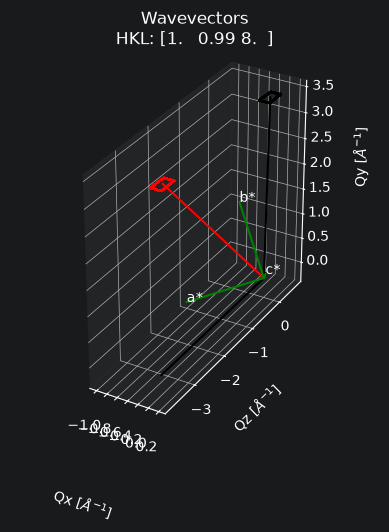

In [39]:
# Plot measurement geometry
scan = data_file_reader(filename)

instrument = scan.instrument_model()

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
instrument.plot_wavevectors(ax)

plt.show()